# IEEE9 inverter comparison: native DPsim, FMI ME, and FMI CS

This notebook presents the IEEE9 results in the same format as the small-grid comparison: summary tables, separate voltage/current error plots, rolling error traces, and close-ups around the load step. It uses the corrected, closed-loop DPsim runs at 100 µs for both 5 s (load step at 2.5 s) and 100 s (load step at 50 s).

Each method starts from the same solved IEEE9 powerflow and inverter operating point. The bus-3 synchronous machine is replaced by the averaged inverter; the remaining generators retain the IEEE9 excitation and governor models. The CS FMU uses rollback/Newton with four midpoint voltage replay substeps and retains its exact exponential current update. Native and ME use trapezoidal integration, so long-run trajectory differences are visible and should not be interpreted as an absolute-accuracy comparison.


In [1]:
from pathlib import Path
import json
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

# Find the DPsim checkout whether Jupyter starts in the repo or this folder.
HERE = Path.cwd().resolve()
ROOT = next((p for p in (HERE, *HERE.parents) if (p / "build-fmi").is_dir()), None)
if ROOT is None:
    raise FileNotFoundError("Open this notebook from a DPsim checkout")

RUNS = {
    "5 s": ROOT / "build-fmi/ieee9-inverter/ieee9-final-5s-100us",
    "100 s": ROOT / "build-fmi/ieee9-inverter/ieee9-corrected-100s-100us",
}
metrics_by_run = {
    label: json.loads((path / "metrics.json").read_text())
    for label, path in RUNS.items()
}
for label, metrics in metrics_by_run.items():
    cfg = metrics["configuration"]
    print(
        f"{label}: {cfg['steps_us'][0]} µs, load step at {cfg['load_step_s']} s; results: {RUNS[label]}"
    )

5 s: 100 µs, load step at 2.5 s; results: /home/matthiasmees/dpsim/build-fmi/ieee9-inverter/ieee9-final-5s-100us
100 s: 100 µs, load step at 50.0 s; results: /home/matthiasmees/dpsim/build-fmi/ieee9-inverter/ieee9-corrected-100s-100us


## Full-run RMS error and timing summary

Errors use native DPsim at the same timestep as the reference. The native row is the zero-error baseline. The pre-step and post-step columns separate the load-step response from the initial operating interval.

In [2]:
rows = []
for duration, metrics in metrics_by_run.items():
    case = metrics["cases"][str(metrics["configuration"]["steps_us"][0])]
    for method in ("me", "cs"):
        run = case["runtimes"][method]
        result = case["comparisons"][method]
        full = result["full_run"]
        before = result["windows"]["pre_load_step"]
        after = result["windows"]["post_load_step"]
        newton = run.get("newton_metrics", {})
        rows.append(
            {
                "Duration": duration,
                "Timestep [µs]": metrics["configuration"]["steps_us"][0],
                "Method": method.upper(),
                "Voltage RMS error [%]": full["voltage_rms_error_percent"],
                "Current RMS error [%]": full["current_rms_error_percent"],
                "Pre-step V error [%]": before["voltage_rms_error_percent"],
                "Pre-step I error [%]": before["current_rms_error_percent"],
                "Post-step V error [%]": after["voltage_rms_error_percent"],
                "Post-step I error [%]": after["current_rms_error_percent"],
                "Mean Newton iterations": newton.get("mean_iterations"),
                "Max Newton iterations": newton.get("max_iterations"),
                "Solver time [s]": run["simulation_s"],
            }
        )
summary = pd.DataFrame(rows)
display(
    summary.style.format({c: "{:.5g}" for c in summary.select_dtypes("number").columns})
)

,Duration,Timestep [µs],Method,Voltage RMS error [%],Current RMS error [%],Pre-step V error [%],Pre-step I error [%],Post-step V error [%],Post-step I error [%],Mean Newton iterations,Max Newton iterations,Solver time [s]
0,5 s,100,ME,3.8559e-06,8.6689e-08,2.0794e-06,5.1427e-08,5.0976e-06,1.0983e-07,2.6706,3,14.7
1,5 s,100,CS,0.31313,0.076773,0.15963,0.032199,0.41781,0.10213,2,2,9.8432
2,100 s,100,ME,7.6943e-05,1.3933e-06,3.9494e-05,7.05e-07,0.00010174,1.8314e-06,2.6716,3,288.12
3,100 s,100,CS,7.4617,1.8524,3.5737,1.0115,9.9636,2.4057,2.0032,3,193


## Full-run RMS error by duration

Separate voltage and current axes keep each quantity readable, as in the small-grid notebook.

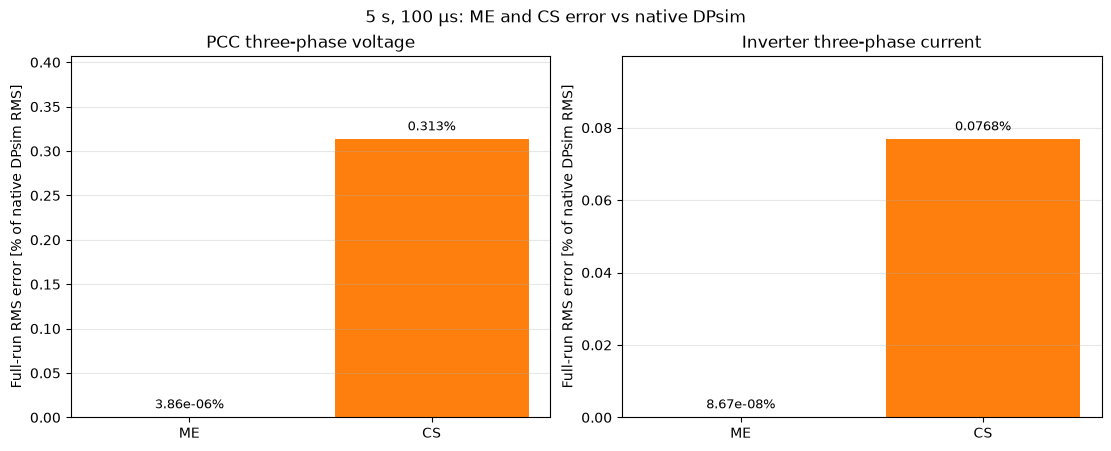

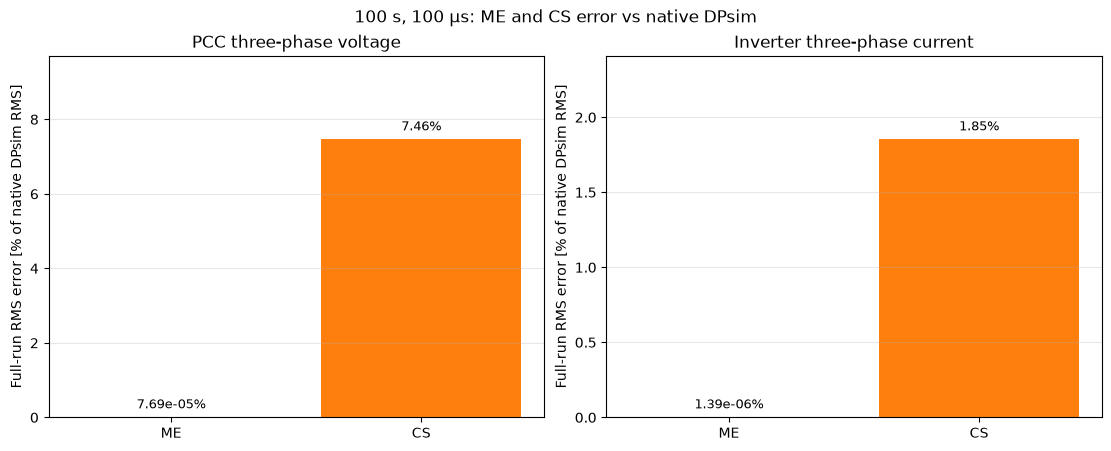

In [3]:
for duration, metrics in metrics_by_run.items():
    case = metrics["cases"][str(metrics["configuration"]["steps_us"][0])]
    fig, axes = plt.subplots(1, 2, figsize=(11, 4.4), constrained_layout=True)
    for ax, quantity, title in zip(
        axes,
        ("voltage", "current"),
        ("PCC three-phase voltage", "Inverter three-phase current"),
    ):
        values = [
            case["comparisons"][m]["full_run"][f"{quantity}_rms_error_percent"]
            for m in ("me", "cs")
        ]
        bars = ax.bar(("ME", "CS"), values, color=("tab:blue", "tab:orange"))
        ymax = max(values) * 1.3 if max(values) else 1e-12
        ax.set_ylim(0, ymax)
        ax.set_ylabel("Full-run RMS error [% of native DPsim RMS]")
        ax.set_title(title)
        ax.grid(True, axis="y", alpha=0.3)
        for bar, value in zip(bars, values):
            ax.text(
                bar.get_x() + bar.get_width() / 2,
                value + ymax * 0.025,
                f"{value:.3g}%",
                ha="center",
                fontsize=9,
            )
    fig.suptitle(f"{duration}, 100 µs: ME and CS error vs native DPsim")
    plt.show()

## Error trajectories

The plots show trailing 100 ms RMS errors relative to the native DPsim trajectory. The vertical marker indicates the load step.

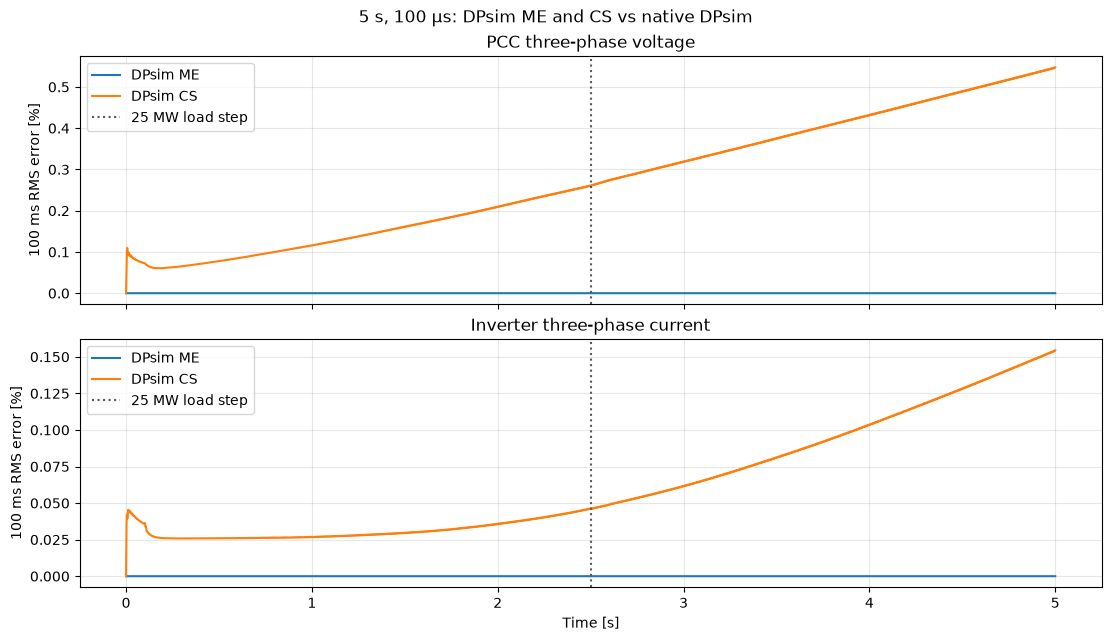

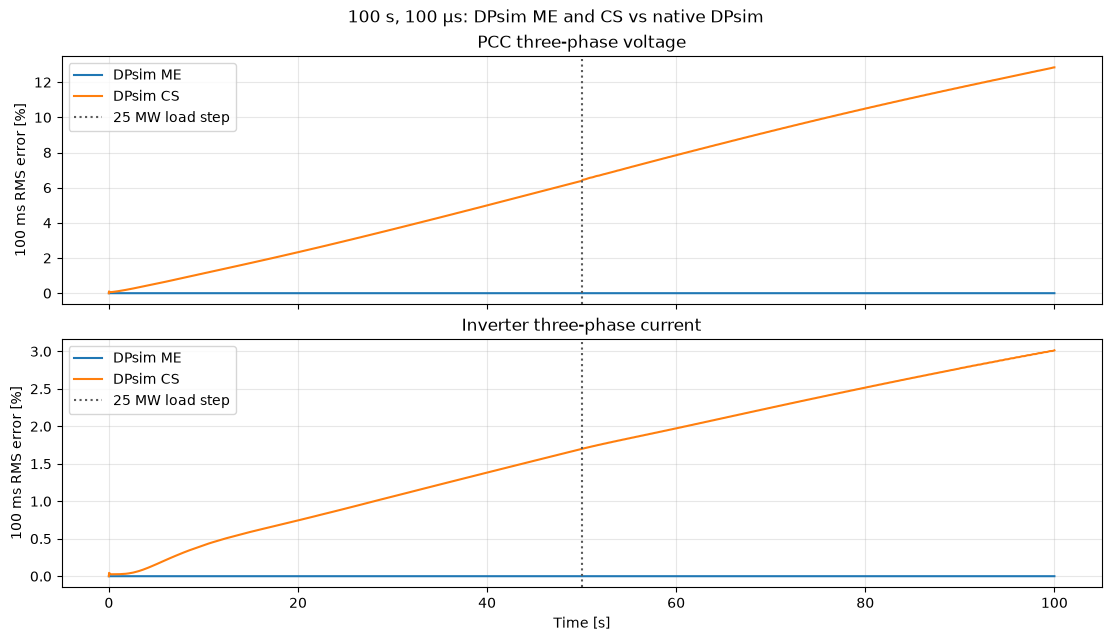

In [4]:
for duration, metrics in metrics_by_run.items():
    case = metrics["cases"][str(metrics["configuration"]["steps_us"][0])]
    event = metrics["configuration"]["load_step_s"]
    fig, axes = plt.subplots(
        2, 1, figsize=(11, 6.3), sharex=True, constrained_layout=True
    )
    for method, color in (("me", "tab:blue"), ("cs", "tab:orange")):
        result = case["comparisons"][method]
        trace = pd.read_csv(result["rolling_error_trace"])
        axes[0].plot(
            trace["time_s"],
            trace["pcc_voltage_rms_error_percent_100ms"],
            color=color,
            label=f"DPsim {method.upper()}",
        )
        axes[1].plot(
            trace["time_s"],
            trace["inverter_current_rms_error_percent_100ms"],
            color=color,
            label=f"DPsim {method.upper()}",
        )
    for ax, title in zip(
        axes, ("PCC three-phase voltage", "Inverter three-phase current")
    ):
        ax.axvline(event, color="0.35", linestyle=":", label="25 MW load step")
        ax.set_ylabel("100 ms RMS error [%]")
        ax.set_title(title)
        ax.grid(True, alpha=0.3)
        ax.legend()
    axes[1].set_xlabel("Time [s]")
    fig.suptitle(f"{duration}, 100 µs: DPsim ME and CS vs native DPsim")
    plt.show()

## Phase-a voltage and inverter current around the load step

Each case shows the same ±5 ms window around the event. The traces come from the retained load-step zoom CSVs, not from replayed network inputs.

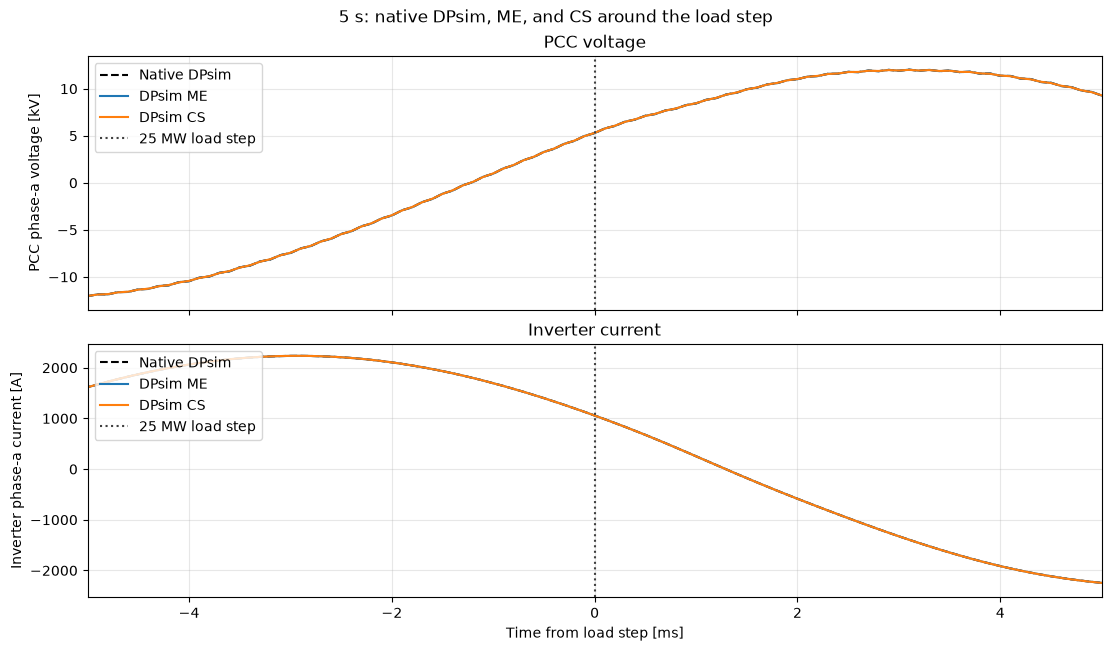

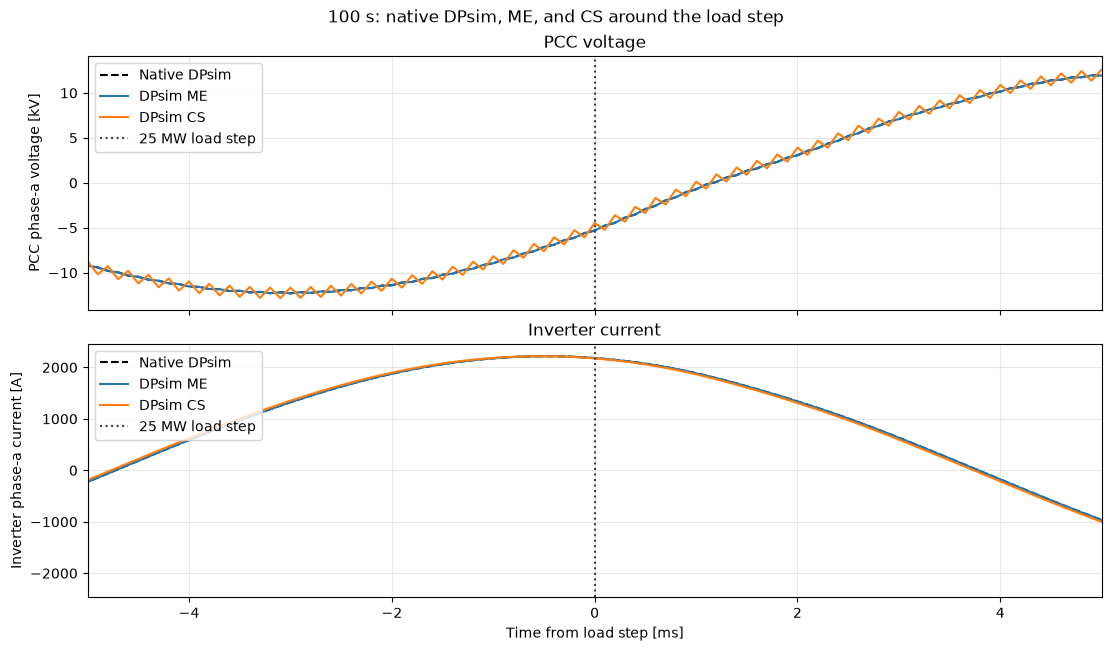

In [5]:
zoom_half_width = 0.005
for duration, metrics in metrics_by_run.items():
    case = metrics["cases"][str(metrics["configuration"]["steps_us"][0])]
    event = metrics["configuration"]["load_step_s"]
    me = pd.read_csv(case["comparisons"]["me"]["load_step_zoom_trace"])
    cs = pd.read_csv(case["comparisons"]["cs"]["load_step_zoom_trace"])
    t = (me["time_s"] - event) * 1000
    fig, axes = plt.subplots(
        2, 1, figsize=(11, 6.4), sharex=True, constrained_layout=True
    )
    axes[0].plot(t, me["native_v_a_V"] / 1000, "k--", label="Native DPsim")
    axes[0].plot(t, me["me_v_a_V"] / 1000, color="tab:blue", label="DPsim ME")
    axes[0].plot(
        (cs["time_s"] - event) * 1000,
        cs["cs_v_a_V"] / 1000,
        color="tab:orange",
        label="DPsim CS",
    )
    axes[1].plot(t, me["native_i_a_A"], "k--", label="Native DPsim")
    axes[1].plot(t, me["me_i_a_A"], color="tab:blue", label="DPsim ME")
    axes[1].plot(
        (cs["time_s"] - event) * 1000,
        cs["cs_i_a_A"],
        color="tab:orange",
        label="DPsim CS",
    )
    axes[0].set_ylabel("PCC phase-a voltage [kV]")
    axes[0].set_title("PCC voltage")
    axes[1].set_ylabel("Inverter phase-a current [A]")
    axes[1].set_title("Inverter current")
    axes[1].set_xlabel("Time from load step [ms]")
    for ax in axes:
        ax.axvline(0, color="0.25", linestyle=":", label="25 MW load step")
        ax.grid(True, alpha=0.3)
        ax.legend(loc="upper left")
    axes[1].set_xlim(-zoom_half_width * 1000, zoom_half_width * 1000)
    fig.suptitle(f"{duration}: native DPsim, ME, and CS around the load step")
    plt.show()

## Interpretation

The short run is tightly aligned: CS and ME errors remain small across the load step. Over 100 s, the CS voltage/current waveform RMS error grows because CS uses the FMU's exact exponential current update while native/ME use trapezoidal integration. The 100 s run remains bounded; it should be presented separately from the five-second comparison. These figures measure agreement between implementations at matched settings, not independent physical accuracy.
